# Baselines (M4): learning check and training curves

The small CNN's learning check (train on one small batch until it fits, before full training), and the training curves
of both baselines. settings come from `config.yaml` and `configs/cnnbaseline.yaml`

Run `hash.py`, `dupe.py`, `standardize.py` and `split.py` first.

In [1]:
import os
import sys
from pathlib import Path

os.environ["KERAS_BACKEND"] = "torch"  # Keras runs the CNN on PyTorch (GPU on Windows), as in cnnbaseline.py: before importing keras

# this notebook lives in notebooks/, so point python at the project modules in src/SeeNN/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())  # repo root
sys.path.insert(0, str(ROOT / "src" / "SeeNN"))
sys.path.insert(0, str(ROOT / "src" / "SeeNN" / "models"))

import keras
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage, display
from PIL import Image

import cnnbaseline
import config
import evaluatebaseline
import pipeline

FIGURES = config.RESULTS_FOLDER / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Learning check (small CNN)

From the M4 guidelines: train the model on one small batch of 8 to 32 training examples, with dropout and any other
regularization turned off, until it predicts every example in that batch correctly and the training loss is close to
zero. A model that can't fit a handful of examples has a bug, usually in the labels, the loss or the output layer.

Here we check 4 scans of each class (16 in total), no dropout and no class weights, 200 updates on the same batch. It passes if all 16 scans are predicted correctly and the final loss is below 0.01.

In [2]:
LC = cnnbaseline.RUN["learning_check"]  # settings from configs/cnnbaseline.yaml
CHECK_CSV = cnnbaseline.RESULTS / "learning_check.csv"


def load_scans(outputs):
    """standardized PNGs as one normalized float32 batch, the same scaling as pipeline.make_dataset"""
    stats = pipeline.load_stats()
    pixels = []
    for output in outputs:
        with Image.open(config.OUTPUT_FOLDER / output) as image:
            pixels.append(np.asarray(image, dtype=np.float32))
    return ((np.stack(pixels) - stats["mean"]) / stats["std"])[..., None]


def learning_check():
    """trains on one small batch over and over, with dropout and class weights off. returns a table with the loss at
    every step, and how many of the batch's scans the model then predicts correctly, in training and inference mode"""
    batch = evaluatebaseline.read_split("train").groupby("class").sample(LC["per_class"], random_state=config.SEED)  # same scans every time
    x, y = load_scans(batch["output"]), batch["class"].map(config.CLASSES.index).to_numpy()
    keras.utils.set_random_seed(config.SEED)
    model = cnnbaseline.build_model(dropout=0.0)  # no dropout
    losses = [float(model.train_on_batch(x, y, return_dict=True)["loss"]) for _ in range(LC["steps"])]
    correct_inference = int((model.predict(x, verbose=0).argmax(axis=1) == y).sum())  # inference mode, as used for val
    train_mode = keras.ops.convert_to_numpy(model(x, training=True))  # training mode, same as the loss (copied off the GPU)
    correct = int((train_mode.argmax(axis=1) == y).sum())
    return pd.DataFrame({"step": range(1, LC["steps"] + 1), "loss": losses, "correct": correct,
                         "correct_inference": correct_inference, "total": len(y)})

reusing learning_check.csv
final loss 0.00013, 16 of 16 scans predicted correctly: PASSED


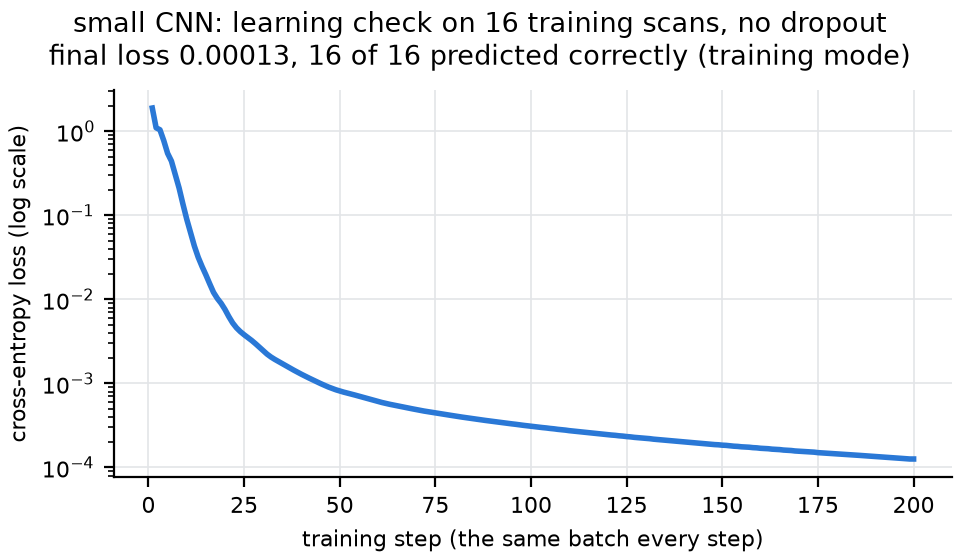

In [3]:
# The result is saved, so later runs reuse it (delete the csv to rerun)
if CHECK_CSV.exists():
    check = pd.read_csv(CHECK_CSV)
    print(f"reusing {CHECK_CSV.name}")
else:
    cnnbaseline.RESULTS.mkdir(parents=True, exist_ok=True)
    check = learning_check()
    check.round(6).to_csv(CHECK_CSV, index=False)

final, correct, total = check["loss"].iloc[-1], check["correct"].iloc[0], check["total"].iloc[0]
passed = correct == total and final <= LC["max_loss"]
print(f"final loss {final:.5f}, {correct} of {total} scans predicted correctly: {'PASSED' if passed else 'FAILED'}")

figure = FIGURES / "learning_check_cnnbaseline.png"
evaluatebaseline.learning_check_figure(check, evaluatebaseline.MODELS["cnnbaseline"], figure)
display(ShowImage(figure))

## 2. Training curves

**small CNN:** train and val loss at each epoch for each seed, from the history files `cnnbaseline.py` saves. the dashed
line marks the epoch with the lowest val loss, whose weights were kept

**HOG + logistic regression:** train and val loss and val macro F1 for each regularization strength C tried, from
`logitbaseline.py`

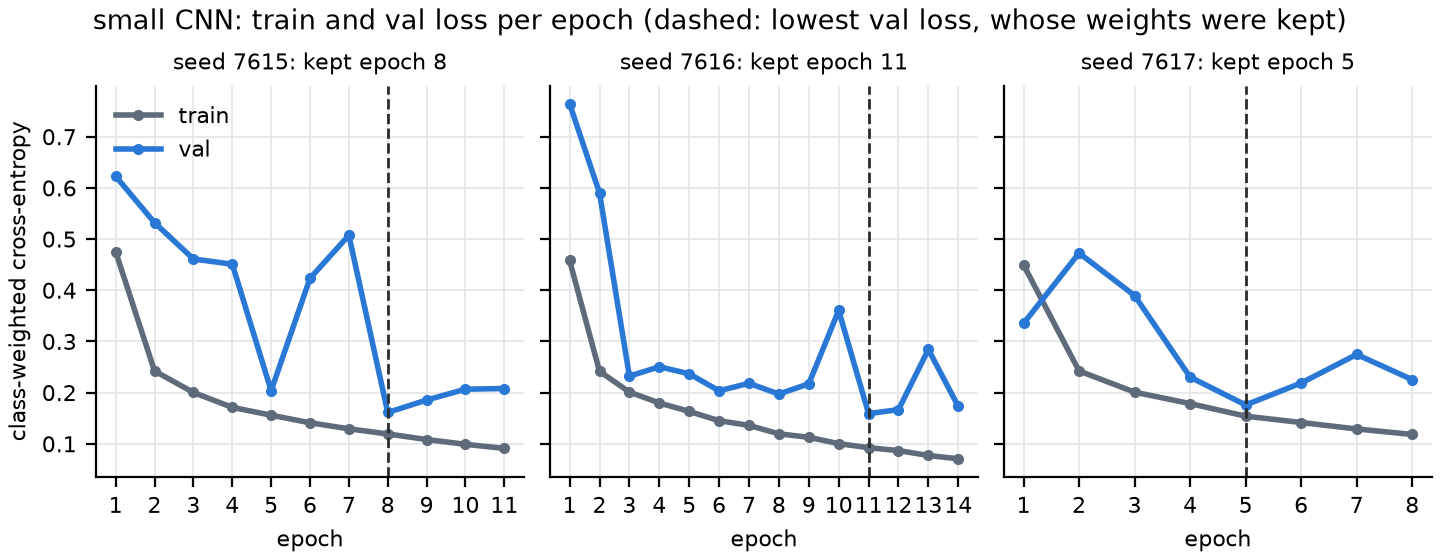

seed 7615: kept epoch 8 of 11 (val loss 0.1612), 225 min
seed 7616: kept epoch 11 of 14 (val loss 0.1590), 258 min
seed 7617: kept epoch 5 of 8 (val loss 0.1759), 150 min


In [4]:
history_files = sorted(cnnbaseline.RESULTS.glob("history_seed*.csv"))
if history_files:
    histories = {path.stem.split("_")[1].removeprefix("seed"): pd.read_csv(path) for path in history_files}
    figure = FIGURES / "loss_curves_cnnbaseline.png"
    evaluatebaseline.loss_curves_figure(histories, evaluatebaseline.MODELS["cnnbaseline"], figure)
    display(ShowImage(figure))
    for seed, history in histories.items():
        best = history.loc[history["chosen"]].iloc[0]
        print(f"seed {seed}: kept epoch {best['epoch']:.0f} of {len(history)} (val loss {best['val_loss']:.4f}), "
              f"{best['train_minutes']:.0f} min")
else:
    print("no CNN training history yet: run src/SeeNN/models/cnnbaseline.py (on a GPU), then rerun this cell")

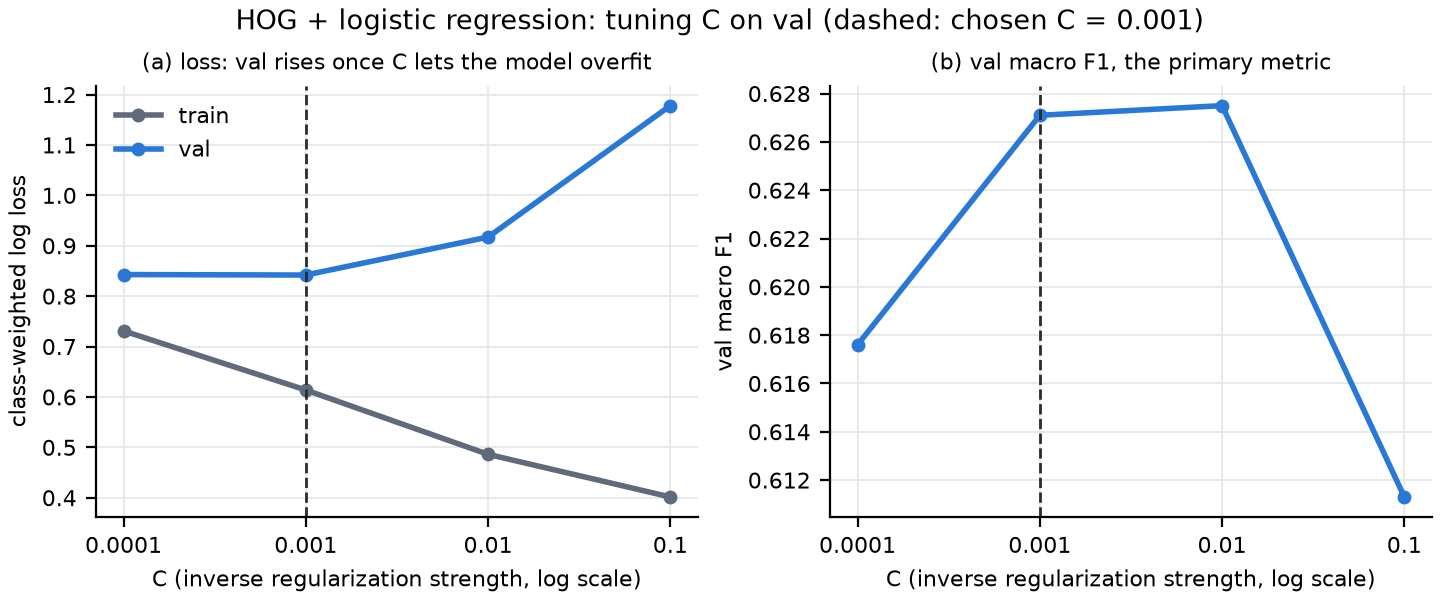

In [5]:
tuning = FIGURES / "tuning_logitbaseline.png"  # drawn by evaluatebaseline.py
if tuning.exists():
    display(ShowImage(tuning))
else:
    print("no tuning figure yet: run src/SeeNN/models/logitbaseline.py")